# Seed Robustness (Llama-3.1-8B)

The L-3 patching experiment repeated on three independently seeded "bad-doctor" fine-tunes of
Llama-3.1-8B with identical LoRA hyperparameters (an adapter family separate from the main
experiment), to check that the shift and its recovery are not an artifact of one training run.

Inputs: `data/outputs/seed_robustness/` (written by `scripts/run_seed_robustness.py`).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from xai_delta import config
from xai_delta.io import load_json

config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

rows = []
for seed in (1, 2, 3):
    d = load_json(config.OUTPUTS_DIR / "seed_robustness" / f"seed{seed}.json")
    rows.append({
        "seed": seed,
        "B(pre)": 100 * d["urgency_B_base"],
        "B(post)": 100 * d["urgency_B_bad"],
        "B(post, patched @ L-3)": 100 * d["urgency_B_patched"],
    })
df = pd.DataFrame(rows).set_index("seed")
df.round(1)

,B(pre),B(post),"B(post, patched @ L-3)"
seed,,,
1,28.7,1.3,30.7
2,28.7,2.7,28.0
3,28.7,2.0,26.0


In [2]:
print(f"B(post) across seeds:          {df['B(post)'].min():.1f}% - {df['B(post)'].max():.1f}%")
print(f"B(post, patched) across seeds: {df['B(post, patched @ L-3)'].min():.1f}% - {df['B(post, patched @ L-3)'].max():.1f}%")
print(f"B(pre) (same reference model): {df['B(pre)'].iloc[0]:.1f}%")

B(post) across seeds:          1.3% - 2.7%
B(post, patched) across seeds: 26.0% - 30.7%
B(pre) (same reference model): 28.7%


saved results/figures/seed_robustness.pdf


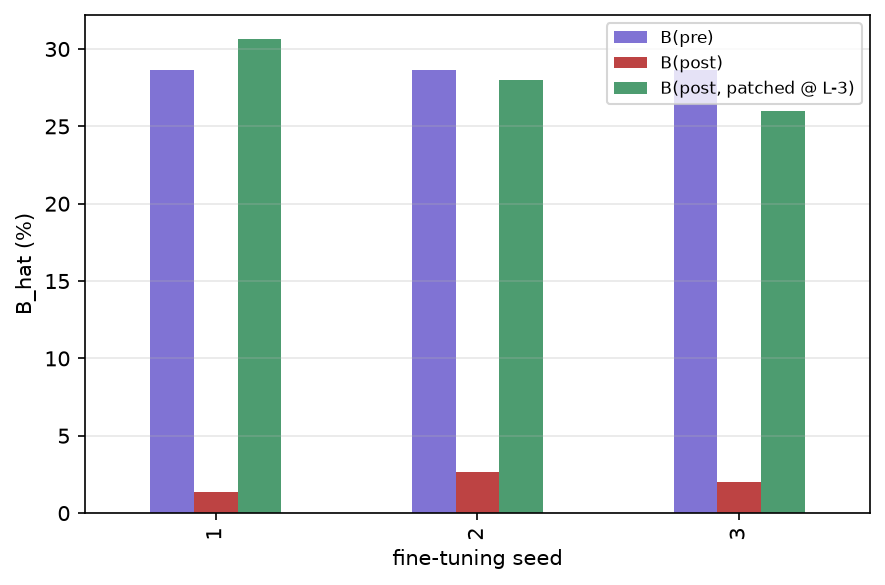

In [3]:
fig, ax = plt.subplots(figsize=(6, 4), dpi=150)
df.plot(kind="bar", ax=ax, color=["slateblue", "firebrick", "seagreen"], alpha=0.85)
ax.set_ylabel("B_hat (%)")
ax.set_xlabel("fine-tuning seed")
ax.legend(fontsize=8)
ax.grid(True, axis="y", alpha=0.3)
fig.tight_layout()
path = config.FIGURES_DIR / "seed_robustness.pdf"
fig.savefig(path, bbox_inches="tight")
print(f"saved {path.relative_to(config.REPO_ROOT)}")
plt.show()

All three seeds show the same pattern: a large drop from $B(M_{pre})$ to $B(M_{post})$ and
near-complete recovery under L-3 patching, both varying only within a narrow band.